In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from CrocoDash.case import Case

In [2]:
# CESM case (experiment) name
casename = "debug.ww3.nyf"

# CESM source root (Update this path accordingly!!!)
cesmroot = Path("~/work/installs/full_regional_cesm").expanduser()

# Place where all your input files go
inputdir = Path.home() / "scratch" / "croc_input" / casename

# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

# Same as the NYF alias, but SWAV -> WW3 (active wave model)
compset = "1850_DATM%NYF_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_WW3"

# 5-day window; configure_forcings/process_forcings derive STOP_N from this range
date_range = ["2020-01-01 00:00:00", "2020-01-06 00:00:00"]

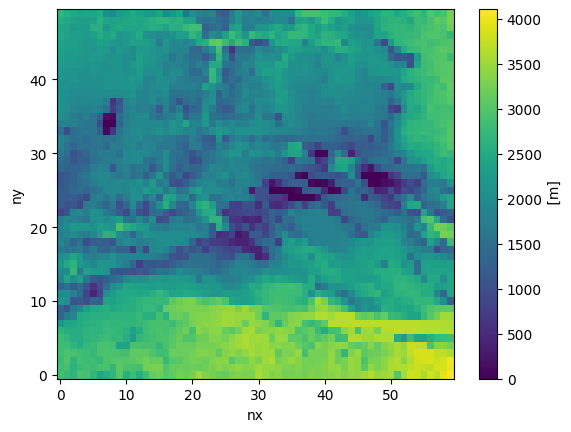

In [3]:
# Small flat-bathymetry grid, just enough to exercise case setup quickly
grid_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_hgrid_open_ocean_nar_10_4ea79c.nc"
bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_topog_open_ocean_nar_10_4ea79c.nc"
grid = Grid.from_supergrid(grid_path)
topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.5,
)
topo.depth.plot()
vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [4]:

case = Case(
    cesmroot=cesmroot,
    caseroot=caseroot,
    inputdir=inputdir,
    compset=compset,
    ocn_grid=grid,
    ocn_topo=topo,
    ocn_vgrid=vgrid,
    atm_grid_name="T62",
    machine="derecho",
    project="ncgd0011",
    override=True,
)


INFO:	initialize:Initializing the visualCaseGen system...
INFO:  csp_solver:CspSolver initialized.


Creating case...

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/full_regional_cesm/cime/scripts/create_newcase --compset 1850_DATM%NYF_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_WW3 --res USER_RES --case /glade/u/home/manishrv/croc_cases/debug.ww3.nyf --machine derecho --run-unsupported --project ncgd0011 

The create_newcase command was successful.

• Updating case xml variables to include newly generated ocean grid "ocean_hgrid_open_ocean_nar_10_4ea79c" with the following properties:
 nx: 60, ny: 50. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/debug.ww3.nyf/ocnice/ESMF_mesh_ocean_hgrid_open_ocean_nar_10_4ea79c_e45523.nc.

./xmlchange OCN_NX=60

./xmlchange OCN_NY=50

./xmlchange OCN_DOMAIN_MESH=/glade/u/home/manishrv/scratch/croc_input/debug.ww3.nyf/ocnice/ESMF_mesh_ocean_hgrid_open_ocean_nar_10_4ea79c_e45523.nc

./xmlchange ICE_NX=60

./xmlchange ICE_NY=50

./xmlchange ICE_DOMAIN_MESH=/glade/u/home/manishrv/scratch/croc_input/debu

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/debug.ww3.nyf.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.

./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric



In [5]:
case.configure_forcings(date_range=date_range)

INFO:CrocoDash.forcing_configurations.base:[SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']
INFO:CrocoDash.forcing_configurations.base:[SKIP] BGC incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] CICE incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIC incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIronForcing incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCRiverNutrients incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] Runoff incompatible with compset
INFO:CrocoDash.forcing_configurations.base:[SKIP] Chl missing args: ['chl_processed_filepath']


Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u

In [7]:
case.process_forcings(process_velocity_tracers=False, process_initial_condition=False)

Case is ready to be built: /glade/u/home/manishrv/croc_cases/debug.ww3.nyf
